<a href="https://colab.research.google.com/github/prasxx18-dev/Deep-Learning-Lab/blob/main/Program_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3964s 23us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 312s 246ms/step - accuracy: 0.4196 - loss: 1.6293 - val_accuracy: 0.4527 - val_loss: 1.5441
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 311s 237ms/step - accuracy: 0.4841 - loss: 1.4512 - val_accuracy: 0.4910 - val_loss: 1.4463
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 322s 237ms/step - accuracy: 0.5049 - loss: 1.3956 - val_accuracy: 0.4940 - val_loss: 1.4379
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 307s 246ms/step - accuracy: 0.5159 - loss: 1.3659 - val_accuracy: 0.5123 - val_loss: 1.3848
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 318s 243ms/step - accuracy: 0.5256 - loss: 1.3374 - val_accuracy: 0.5008 - val_loss: 1.4126
313/313 ━━━━━━━━━━━━━━━━━━━━ 60s 191ms/step - accuracy: 0.4988 - loss: 1.4193
Test Accuracy: 49.880000948905945 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Actual: cat
Predicted: frog
Training Accuracy: 52.560001611709595 %
Validation 

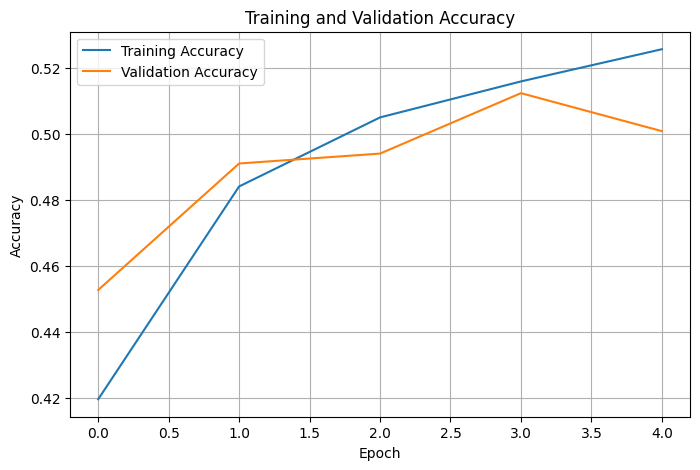

In [1]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()


y_train = y_train.flatten()
y_test = y_test.flatten()


x_train = tf.image.resize(x_train, (96, 96))
x_test = tf.image.resize(x_test, (96, 96))


base_model = tf.keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)


base_model.trainable = False


model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])


model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)


loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy * 100, "%")


prediction = model.predict(x_test[:1])

classes = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

predicted_class = np.argmax(prediction)

print("Actual:", classes[y_test[0]])
print("Predicted:", classes[predicted_class])


train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]

print("Training Accuracy:", train_accuracy * 100, "%")
print("Validation Accuracy:", val_accuracy * 100, "%")


loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Accuracy:", test_accuracy * 100, "%")


plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()